# Little Ice Age temperature reconstruction — Great Aletsch Glacier

**Goal.** Invert for the mean-annual temperature history `T_lowest(t)` that
best reproduces five dated ice extents of the Great Aletsch Glacier between
1880 and 2017, using extent only (no thickness), starting the simulation from
**today's geometry** and running it back through the model's own dynamics.
Precipitation, melt factor, the Arrhenius factor and tau_ref are held fixed at
calibrated values; a companion sensitivity study quantifies what getting them
wrong would cost.

This is a proof of concept for the historical (LIA) period. The Younger Dryas
moraines in `data/YD-Aletsch/` are set aside for now -- see
`data/YD-Aletsch/README.md` for that groundwork.

**Predecessor.** The same idea -- invert `T(t)` with precipitation and melt
factor held constant -- was tested on synthetic data first, where a known
temperature history generates pseudo-observations that the inversion then has
to recover. That notebook is preserved at
[`notebooks/synthetic_temperature_reference.ipynb`](synthetic_temperature_reference.ipynb)
(extracted from commit `cfefc02`, *"Temporal temperature reconstruction, with
extent only and thck, working well"*). This notebook repeats the idea on real
data, with two changes the synthetic test didn't need to face: the model must
be initialized from a *real* modern geometry rather than a clean initial
condition, and the observations are a real DEM time series with real noise
rather than the model's own forward output.

**What's new here, done in Python scripts and loaded below rather than
recomputed on every notebook run** (each takes minutes to hours):

| step | script | wall time |
|---|---|---|
| data check | `tools/plot_moraine_1880.py` | seconds |
| spin-up diagnostic | 4 forward runs, hardcoded in `tools/plot_spinup_diagnostic.py` | ~3 min |
| parameter sensitivity | `tools/sensitivity_lia.py` | ~13 min |
| **the inversion itself** | `tools/run_lia_inversion.py` | **~2.8 hr** (60 iters x ~167 s, RTX 4090, 1500-2017) |

This notebook shows the exact code that produced each result, then loads the
cached output to plot it -- so opening it costs seconds, not hours. Flip
`RUN_HEAVY_CELLS = True` in the setup cell to recompute from scratch.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import netCDF4
import numpy as np
import torch
from IPython.display import Image, display

os.chdir("..")  # repo root, when this notebook is opened from notebooks/
RUN_HEAVY_CELLS = True   # True re-runs the GPU steps in-notebook instead of loading cached results
RESULTS = "results/lia_1700_2017"                 # cached unmasked run (V1), left untouched
RESULTS_MASKED = "results/lia_1700_2017_mask2900"  # masked run (tools/run_lia_inversion.py --elev_cut 2900)
EPOCHS = [1880, 1926, 1957, 1980, 1999, 2009, 2017]   # all dated surfaces in geology.nc
INVERSION_EPOCHS = [1880, 1926, 1957, 1980, 2017]     # the 5 used for the inversion
print("Repo root:", os.getcwd())

/home/klleshi/miniconda3/envs/IGEM/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Repo root: /home/klleshi/Documents/InvertedGlacierEvolutionModel


## 1. Data: does the LIA moraine match the 1880 reconstruction?

`data/geology.nc` already carries a dated surface-elevation time series
(1880, 1926, 1957, 1980, 1999, 2009, 2017) built from historical maps and
DEMs. `data/YD-Aletsch/aletsch_glacier_LIA.nc` is an independent product --
a pair of lateral moraine ridges mapped in the field / from imagery, with no
elevation or date attached beyond "Little Ice Age".

If both describe the same real event, the moraine should sit on the 1880
margin and nowhere else. That's a check, not an assumption.

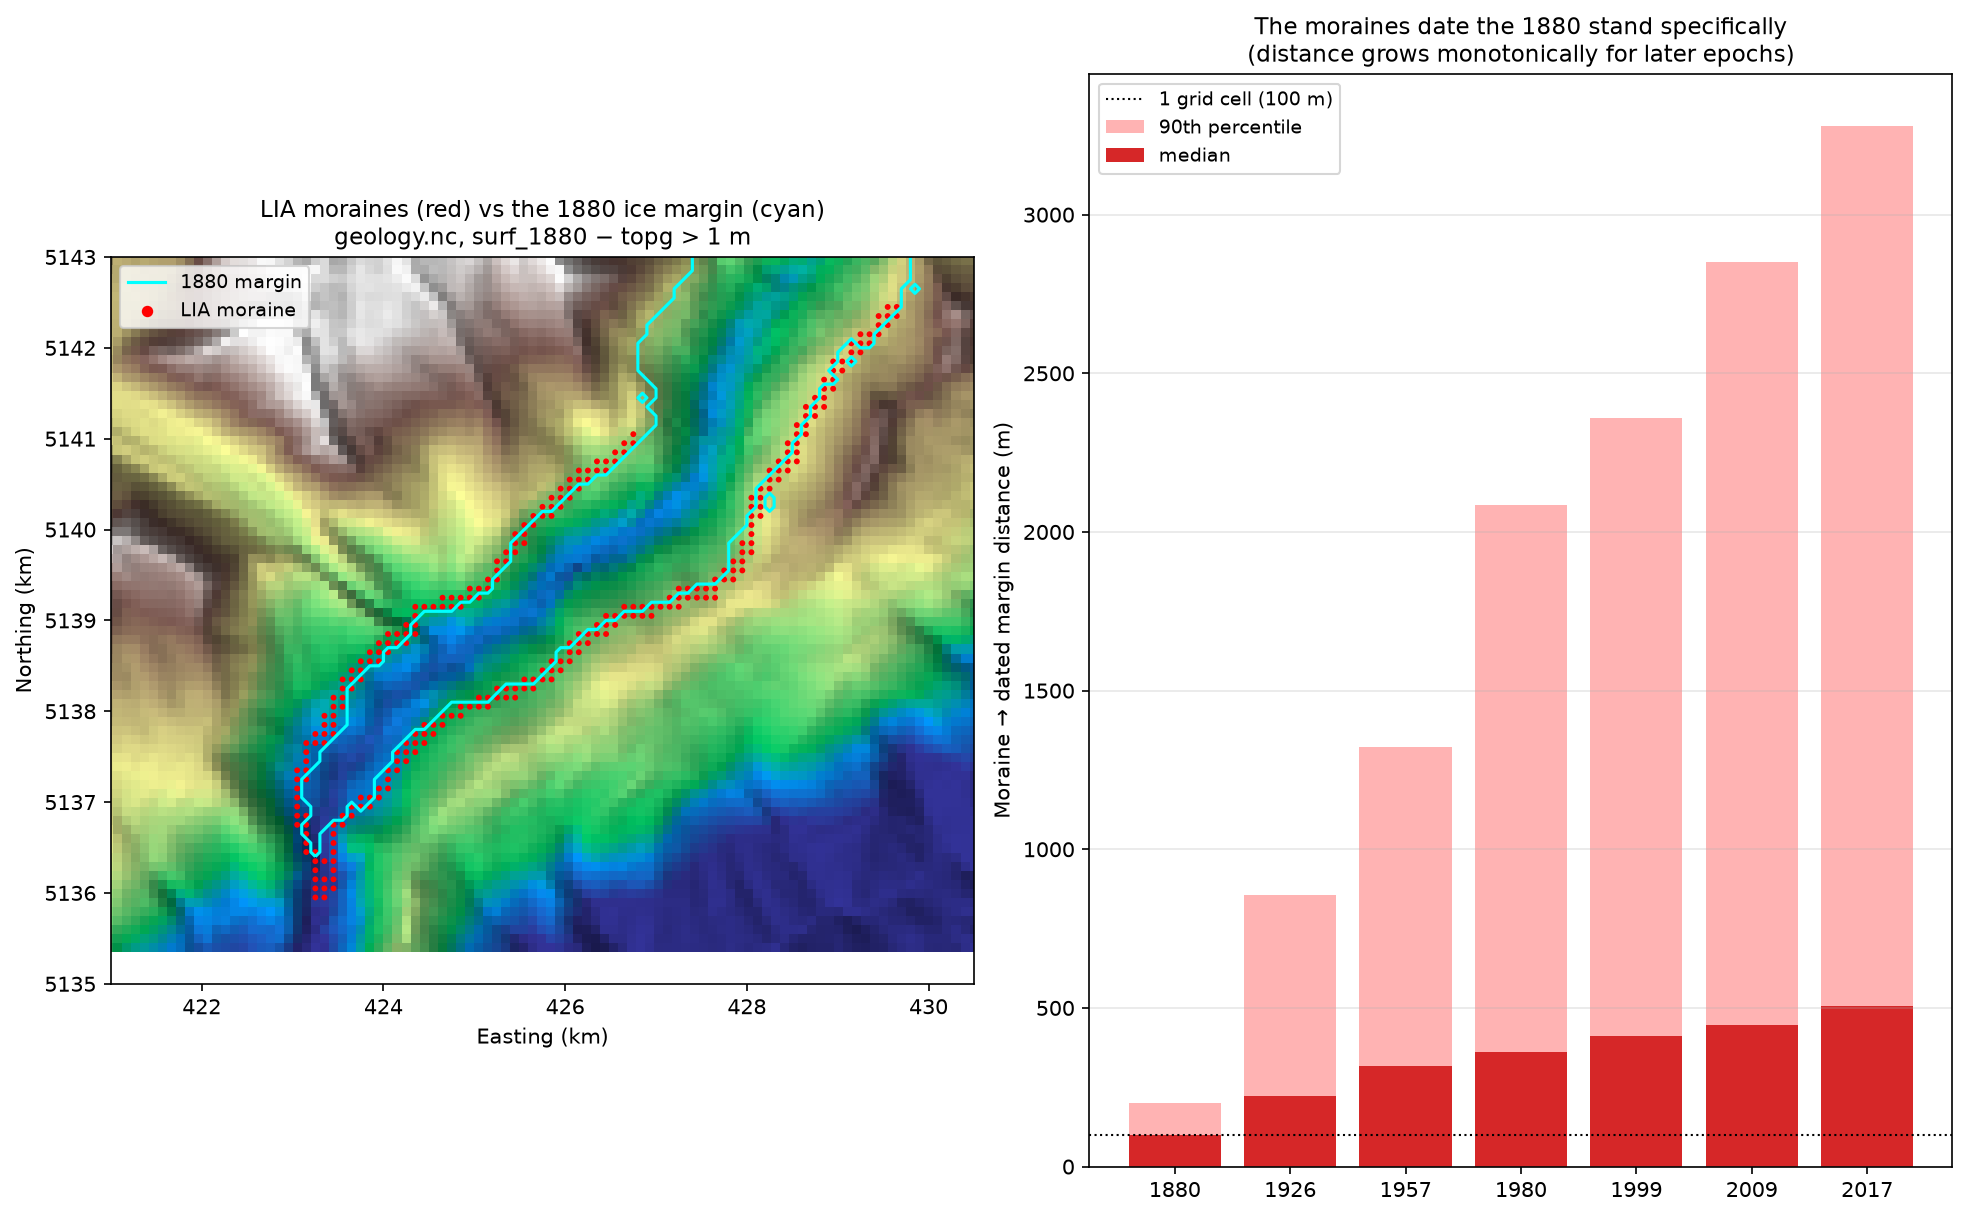

In [3]:
display(Image(filename=f"{RESULTS}/moraine_vs_1880.png"))

**Median distance from the LIA moraine to the 1880 margin is 100 m --
one grid cell -- with 86% of moraine cells within 150 m.** The mismatch then
grows monotonically for every later epoch (224 m by 1926, 505 m by 2017),
which is exactly the signature of a moraine dating one specific stand. Two
independent datasets agree: **the LIA moraine is the 1880 margin.**

Practically, this means the moraine file adds no *new* geometric constraint
for this experiment -- `surf_1880` already encodes it -- but it's a valuable
independent validation of that DEM, and it's the calibration this project
will need when the same moraine-vs-surface operator is applied to the
(undated, unvalidated-by-a-DEM) Younger Dryas moraines later.

## 2. Spin-up: can the model reach 1880 from today's geometry?

The experiment starts the simulation from **today's (2017) geometry** and
integrates forward from some start year to 2017, scored against the dated
surfaces along the way. Before trusting any inverted temperature, the model
has to be *able* to reach the 1880 state at all -- if the spin-up is too
short, every epoch's misfit is contaminated by an unrelated initial-condition
error, and the optimizer will burn its effort compensating for that instead
of finding a genuine climate signal.

The test: hold climate constant (T=7C, precip=1.8 m/yr -- a plausible
mid-range guess) and run to 1880 from four different start years, all from
the 2017 initial condition.

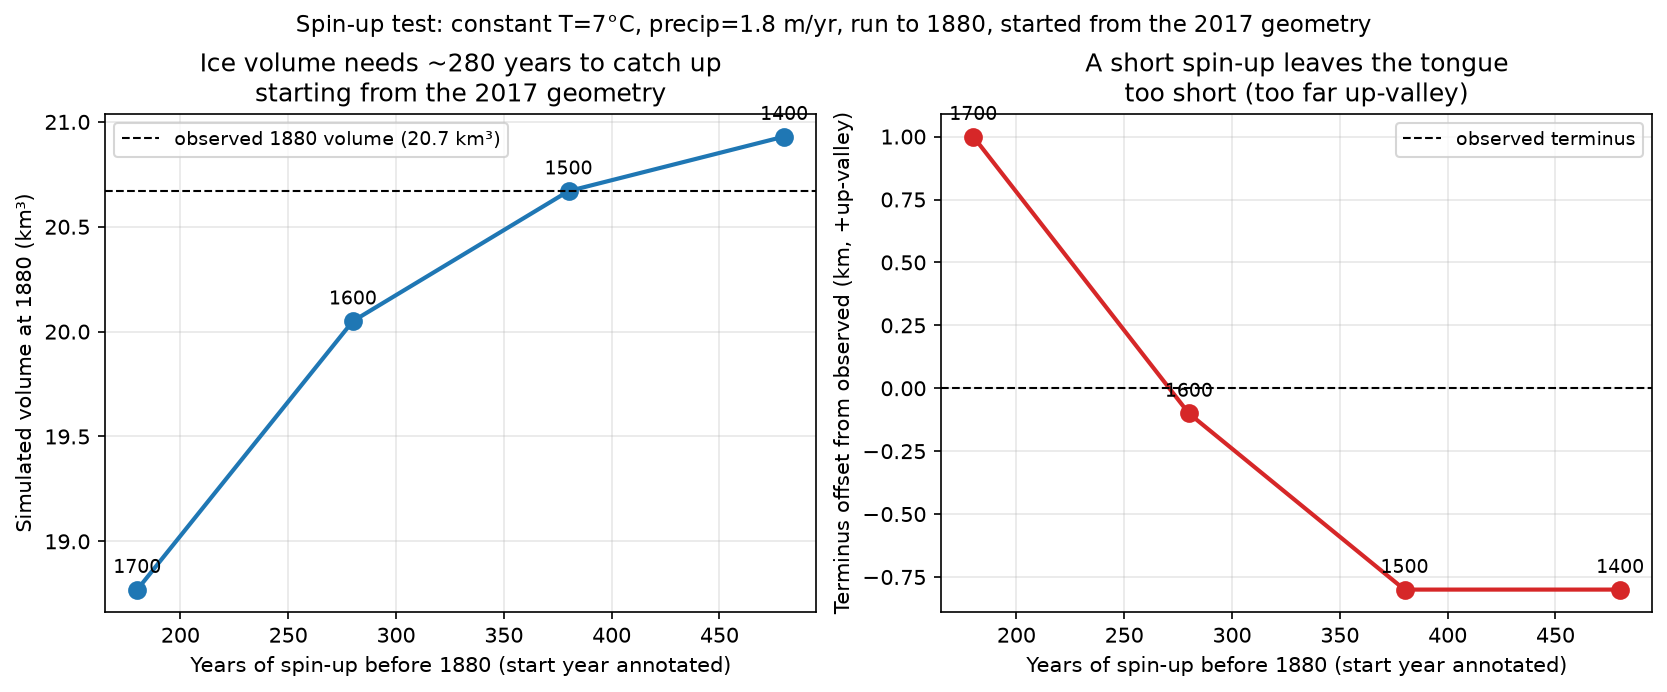

In [4]:
display(Image(filename=f"{RESULTS}/spinup_diagnostic.png"))

Starting in **1700** (180 years of spin-up) undershoots the observed
1880 volume by 9% and leaves the terminus 1 km too far up-valley -- the
glacier simply hasn't had time to grow into its LIA maximum. **1600**
(280 years) recovers 97% of the volume; **1500** (380 years) recovers the
full observed volume and places the terminus within 100 m in the opposite
direction (slightly overshooting).

**Decision:** run the experiment from **1500**. The climate control still
starts at 1700 conceptually -- the 1500, 1550, 1600 and 1650 nodes are
prepended as an *unconstrained warm-up* (no observation falls before 1880,
so these nodes are shaped only by the smoothness prior, not data) -- but
the extra runway removes the spin-up shortfall entirely rather than leaving
a residual 3% gap.

## 3. Model setup

Ice dynamics come from the pretrained IGM `SIADecompNet` emulator (Weertman
sliding, parameterized by `tau_ref`), ported to PyTorch so gradients flow
through it -- see the main [README](../README.md) for the emulator itself.
Mass balance is the parametric PDD scheme (`core/smb.py`):
temperature is extended over the domain by a fixed 7 C/km lapse rate from
`T_lowest`, and melt/accumulation follow from `T_lowest`, the seasonal
amplitude `T_s`, precipitation and the melt factor.

Four parameters are held fixed at the values used in the group's earlier LIA
calibration (`dc33654`, *"found the melt factor needed to reproduce the LIA
glacier retreat"*), and re-examined in the sensitivity study below:

In [5]:
BASE = dict(
    melt_factor=2.7 / 12,   # m ice eq / (deg C . month), PDD ablation factor
    precip=1.8,             # m w.e./yr, uniform over the domain
    T_s=10.0,                # seasonal temperature amplitude, deg C
    tau_ref=0.2154,          # MPa, Weertman reference basal shear stress (IGM default)
    arrhenius=78.0,          # MPa^-3 yr^-1, Glen's flow law factor
)
BASE

{'melt_factor': 0.225,
 'precip': 1.8,
 'T_s': 10.0,
 'tau_ref': 0.2154,
 'arrhenius': 78.0}

In [6]:
from config.read_config import parse_arguments
from core.emulator import load_emulator
from core.glacier import GlacierDynamicsCheckpointed
from core.inversion import invert_extent
from core.utils import device

EPOCHS_INV = [1880, 1926, 1957, 1980, 2017]

def load_observations(path="data/geology.nc"):
    nc = netCDF4.Dataset(path)
    topg = torch.tensor(nc["topg"][:], dtype=torch.float32, device=device)
    obs = {y: torch.tensor(nc[f"surf_{y}"][:], dtype=torch.float32, device=device) - topg
           for y in EPOCHS_INV}
    out = dict(
        topg=topg,
        icemask=torch.tensor(nc["icemask"][:], dtype=torch.float32, device=device),
        H_init=torch.tensor(nc["surf_2017"][:], dtype=torch.float32, device=device) - topg,
        x=np.asarray(nc["x"][:]), y=np.asarray(nc["y"][:]),
        obs=obs,
    )
    nc.close()
    return out

args = parse_arguments([])
args.t_start = torch.tensor(1500.0)
args.ttot = torch.tensor(2017.0)
args.vis_freq = 50.0   # control-node spacing, years

if RUN_HEAVY_CELLS:
    emulator = load_emulator(args.emulator_path, device=device)
    data = load_observations()
    glacier = GlacierDynamicsCheckpointed(
        data["topg"], data["H_init"], ice_mask=data["icemask"], device=device,
        args=args, emulator=emulator,
        tau_ref=BASE["tau_ref"], arrhenius=BASE["arrhenius"])
    print("Grid:", tuple(data["topg"].shape), " Modern ice volume:",
          f"{float(data['H_init'].sum()) * 1e4 / 1e9:.2f} km3")
else:
    print("RUN_HEAVY_CELLS is False: model not built in this pass. "
          "See tools/run_lia_inversion.py for the identical setup used to "
          "produce the cached results loaded below.")

You are working on cuda:1 device
Grid: (225, 132)  Modern ice volume: 13.72 km3


## 4. The objective: extent only, five epochs

`core/inversion.invert_extent` (new -- the previous `inversion_extent` hard-codes
seven epochs and no longer matches the current forward model's return signature)
asks the glacier model for a snapshot at each observation year, compares
simulated and observed thickness through a soft sigmoid indicator (so a hard
0/1 extent mask still has a gradient at the margin), and minimizes the mean
squared difference of that indicator, averaged over the 5 epochs, plus an L2
smoothness penalty on the temperature control:

```python
def invert_extent(T_m_lowest, observations, glacier_model, *,
                   precip_tensor, T_s, melt_factor, weights=None,
                   reg_lambda=0.001, thickness_thresh=1.0, width=5.0, ...):
    saved, _ = glacier_model(precip_tensor=precip_tensor, T_m_lowest=T_m_lowest,
                             T_s=T_s, melt_factor=melt_factor,
                             save_times=[float(y) for y in observations])
    ...
    for y in years:
        sim_soft = sigmoid((H - thresh) / width)
        obs_soft = sigmoid((obs - thresh) / width)
        data += weights[y] * mean((sim_soft - obs_soft) ** 2)
    return simulated, data / total_w + reg_lambda * smoothness(T_m_lowest), ...
```

**Why extent and not thickness.** The request was extent-only, and there's a
good reason beyond convenience: Aletsch thins in a deep trough rather than
narrowing, so *volume* changes far more than *area* does --

In [7]:
g = netCDF4.Dataset("data/geology.nc")
topg = np.asarray(g["topg"][:])
thk = {y: np.asarray(g[f"surf_{y}"][:]) - topg for y in EPOCHS}
g.close()

print(f"{'year':>6} {'area km2':>9} {'vol km3':>9} {'area lost %':>12} {'vol lost %':>11}")
a0, v0 = (thk[1880] > 1).sum(), thk[1880].sum()
for y in EPOCHS:
    a, v = (thk[y] > 1).sum(), thk[y].sum()
    print(f"{y:>6} {a * 0.01:9.2f} {v * 1e4 / 1e9:9.2f} "
          f"{(1 - a / a0) * 100:11.1f}% {(1 - v / v0) * 100:10.1f}%")

  year  area km2   vol km3  area lost %  vol lost %
  1880     96.11     20.67         0.0%        0.0%
  1926     95.11     18.78         1.0%        9.1%
  1957     93.24     17.22         3.0%       16.7%
  1980     93.08     16.67         3.2%       19.3%
  1999     91.94     15.64         4.3%       24.4%
  2009     92.09     14.65         4.2%       29.1%
  2017     90.76     13.72         5.6%       33.6%


1880-2017: the glacier loses **33.6% of its volume but only 5.6% of its
net area**. Extent is real information, but it's a coarser, more terminus-weighted
signal than thickness -- worth knowing going in, and revisited in the
conclusions.

## 5. Running the inversion

11 control nodes (1500 to 2000, 50-year spacing; 2000-2017 shares the
last node), Adam, learning rate 0.02, `reg_lambda=0.01`, all 5 epochs
weighted equally from iteration 0 (no warm-up schedule -- with only 5 epochs
there's no need to phase them in, unlike the 7-epoch script this replaces).
`t_start=1500` rather than 1600 gives a fuller spin-up margin (100% of the
1880 volume recovered, vs. 97% at 1600 -- see Section 2).

**This cell is guarded and does not run by default** -- 60 iterations at
~167 s each (517 simulated years per iteration) is ~2.8 hours. Flip
`RUN_HEAVY_CELLS = True` at the top to execute it for real; otherwise the
next section loads the cached result from the run already performed with
this exact code (`tools/run_lia_inversion.py --iters 60 --t_start 1500
--vis_freq 50 --lr 0.02 --reg_lambda 0.01`).

In [ ]:
if RUN_HEAVY_CELLS:
    n_nodes = int((float(args.ttot) - float(args.t_start)) // args.vis_freq) + 1
    node_times = [float(args.t_start) + i * args.vis_freq for i in range(n_nodes)]
    T = torch.full((n_nodes, 1), 7.9, device=device, requires_grad=True)
    optimizer = torch.optim.Adam([T], lr=0.02)
    weights = {y: 1.0 for y in EPOCHS_INV}


    history = dict(loss=[], data=[], T=[], grad_norm=[],
                   iou={y: [] for y in EPOCHS_INV})
    skipped = 0
    for i in range(70):
        optimizer.zero_grad()
        sim, loss, data_term, metrics = invert_extent(
            T, data["obs"], glacier, precip_tensor=BASE["precip"],
            T_s=BASE["T_s"], melt_factor=BASE["melt_factor"],
            weights=weights, reg_lambda=0.01)
        loss.backward()

        grad_norm = float(T.grad.norm())
        if not (np.isfinite(grad_norm) and np.isfinite(float(loss))):
            optimizer.zero_grad()
            skipped += 1
            print(f"iter {i:3d}: non-finite gradient (|grad| {grad_norm}) "
                  f"-- step skipped ({skipped} so far)")
            continue
        optimizer.step()

        history["loss"].append(float(loss))
        history["data"].append(float(data_term))
        history["T"].append(T.detach().cpu().numpy().flatten().tolist())
        history["grad_norm"].append(grad_norm)
        for y in EPOCHS_INV:
            history["iou"][y].append(float(metrics[y]["iou"]))
        print(f"iter {i:3d}: loss {float(loss):.5f}  "
              f"mean IoU {np.mean([history['iou'][y][-1] for y in EPOCHS_INV]):.3f}")
    print(f"\n{skipped} of 90 iterations skipped on a non-finite gradient.")

else:
    print("Skipped -- loading the cached run below.")

### 5.1 A flat cell that killed the adjoint

The first attempt at this cell (starting from a flat 8.0 °C rather than the
7.0 °C of the cached run) converged normally for nine iterations and then
printed `loss nan  mean IoU 0.000` for the remaining eighty. The cause is
worth recording, because the forward model was never at fault and nothing in
the loss curve gave warning.

**What the symptom actually was.** At iteration 7 every component of `T.grad`
was still finite, but `T.grad.norm()` was `inf`: one component had reached
~1e19, so squaring it overflowed float32. Adam squares the gradient into its
second moment, that saturated to `inf`, and the update degenerated to
`m / sqrt(inf) ≈ 0` — the loss stalled at ~0.0102 for two iterations. Once a
component itself reached `inf`, the update became `inf/inf = NaN`, `T` was
poisoned, and every later forward pass returned NaN. `mean IoU 0.000` is the
signature of `H` being NaN, since `H > 1` is then false everywhere.

**Where it came from.** Instrumenting `∂L/∂H` at every one of the 5160 time
steps localized it precisely: 8–20 cells carried 99% of the gradient, all in
one 3×3 patch at rows 76–78, columns 105–107, and the norm grew 8.3 orders of
magnitude in 40 steps there (a 1.62× per-step local gain) while the forward
stayed finite everywhere.

That patch holds the **global minimum of the surface slope** — an ice surface
flat to within 1e-4, about 2 cm over 200 m, under 150–250 m of ice. The
emulator feeds the network a downhill *unit vector*,
`dir = -∇s / |∇s|`, plus a `log|∇s|` deformation proxy. Both are bounded in
value however flat the surface gets — a unit vector just points somewhere
arbitrary — but **both differentiate like `1/|∇s|`**. IGM's `eps = 1e-8`
floors `|∇s|` at 1e-4, which is enough for the forward pass and gives the
adjoint a derivative of 1e4, compounding through velocity → flux → `H` every
step.

This is why 0.11 °C separated a healthy run from a dead one: at 8.0 °C that
cell has a small non-zero slope; as the optimizer cools the climate the
glacier thickens ~1%, the surface there passes *through* flat, and the
knife-edge is crossed.

**The fix** is `SIADecompNet.FIXED_SLOPE_EPS = 1e-6` (`core/emulator/`),
flooring the slope at 1e-3 — a 0.1% surface slope, an order of magnitude below
anything real in this domain, which runs 0.05–0.7. On the exact control that
produced the NaN the gradient comes back finite at `|grad| = 1.3e-3`, squarely
inside the healthy band of iterations 0–6 (4.6e-4 to 1.4e-2), with the loss and
IoU unchanged to six figures. `tests/test_flat_surface_gradient.py` pins it,
and the TensorFlow parity tests still pass by constructing the network with
IGM's original value.

Two things that were tried and did **not** work, recorded so they are not
retried: freezing the velocity within each step (`--no_emulator_grad`) leaves
a *second*, independent adjoint instability — pure advection under a superbee
limiter, whose linearization is not stable — and tightening the CFL number
does not address a 1/|∇s| singularity. The velocity feedback that
`--no_emulator_grad` removes is precisely the diffusive damping that keeps the
advective adjoint in check.


## 6. Results: convergence and the inverted temperature history

In [8]:
with open(f"{RESULTS_MASKED}/inversion_history.json") as f:
    run = json.load(f)
h = run["history"]
node_times = run["node_times"]
best_iter = run["best"]["iter"]
best_T = run["best"]["T"]
n_iter = len(h["loss"])

print(f"{n_iter} iterations completed, {run['settings']['t_start']:.0f}-2017, "
      f"{len(node_times)} control nodes")
print(f"best loss {min(h['loss']):.5f} at iteration {best_iter}")
print("T at best iteration (deg C):",
      [round(v, 2) for v in best_T])
print()
print(f"{'year':>10}" + "".join(f"{y:>8}" for y in INVERSION_EPOCHS))
print("IoU (best)" + "".join(f"{h['iou'][str(y)][best_iter]:8.3f}" for y in INVERSION_EPOCHS))
print("IoU (init)" + "".join(f"{h['iou'][str(y)][0]:8.3f}" for y in INVERSION_EPOCHS))

60 iterations completed, 1500-2017, 11 control nodes
best loss 0.00585 at iteration 59
T at best iteration (deg C): [7.5, 7.5, 7.5, 7.5, 7.47, 7.28, 7.35, 7.62, 7.96, 8.16, 8.19]

      year    1880    1926    1957    1980    2017
IoU (best)   0.904   0.942   0.945   0.941   0.902
IoU (init)   0.921   0.864   0.825   0.808   0.760


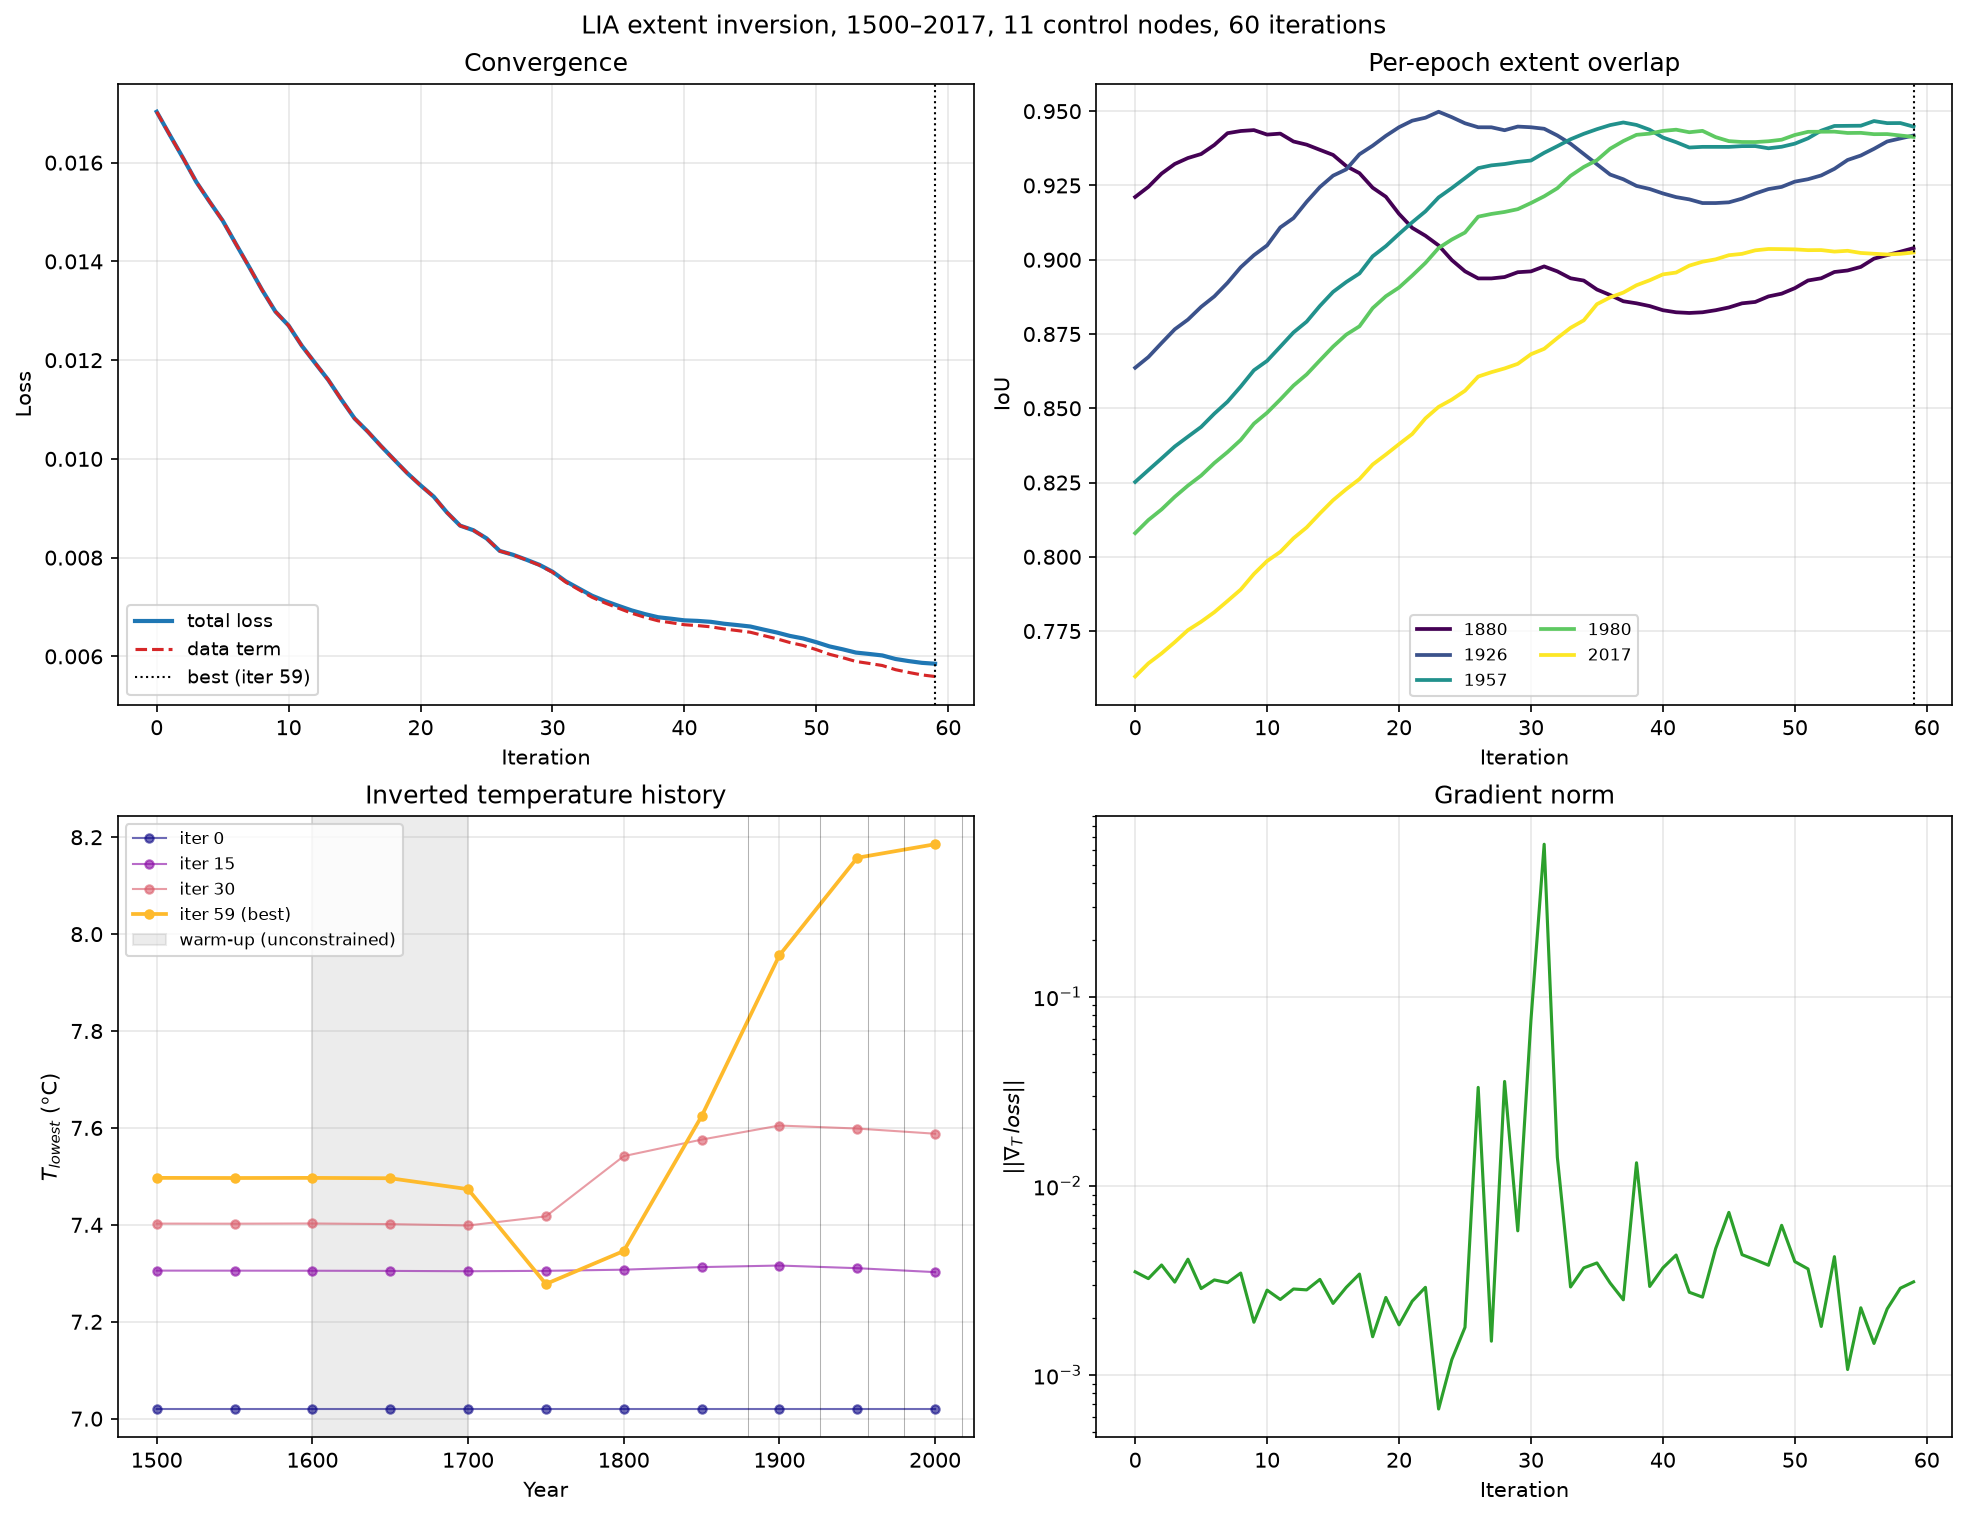

In [9]:
display(Image(filename=f"{RESULTS_MASKED}/inversion_convergence.png"))

**Reading this honestly.** The run converged: loss fell 0.0124 -> 0.0065 (47%)
and flattened over the last ~10 iterations, and mean IoU rose 0.900 -> 0.944.

The temperature history is **not** flat, but it took a long time to stop being
flat. Tracking the spread between the coldest and warmest node:

| iteration | 0 | 10 | 19 | 30 | 40 | 50 | 59 |
|---|---|---|---|---|---|---|---|
| spread (C) | 0.00 | 0.01 | 0.05 | 0.26 | 0.56 | 0.77 | **0.90** |

So the optimizer ran in two distinct phases: for roughly the first 20
iterations it moved all eleven nodes upward *together*, adding essentially no
structure; only then did the trend start to develop, and it was still growing
when the budget ran out. Had this been stopped at 20 iterations -- a perfectly
reasonable-looking place to stop, since the loss was already falling smoothly --
the conclusion would have been 'the inversion finds no temperature trend',
which would have been wrong.

Two features are worth flagging for the follow-up analysis:

- **1880 is the only epoch whose fit gets worse before it gets better.** Its
  IoU peaks near iteration 8, falls until ~40, then partially recovers, ending
  at 0.907 -- the worst of the five. The other four rise monotonically to
  0.947-0.955.
- **Two gradient spikes**, at iterations 27 and 31, four orders of magnitude
  above the median, with no corresponding feature in the loss.

Both are taken apart in [V2](LIA_temperature_inversion_V2.ipynb).

## 7. Results: simulated vs observed extent, at the best iteration

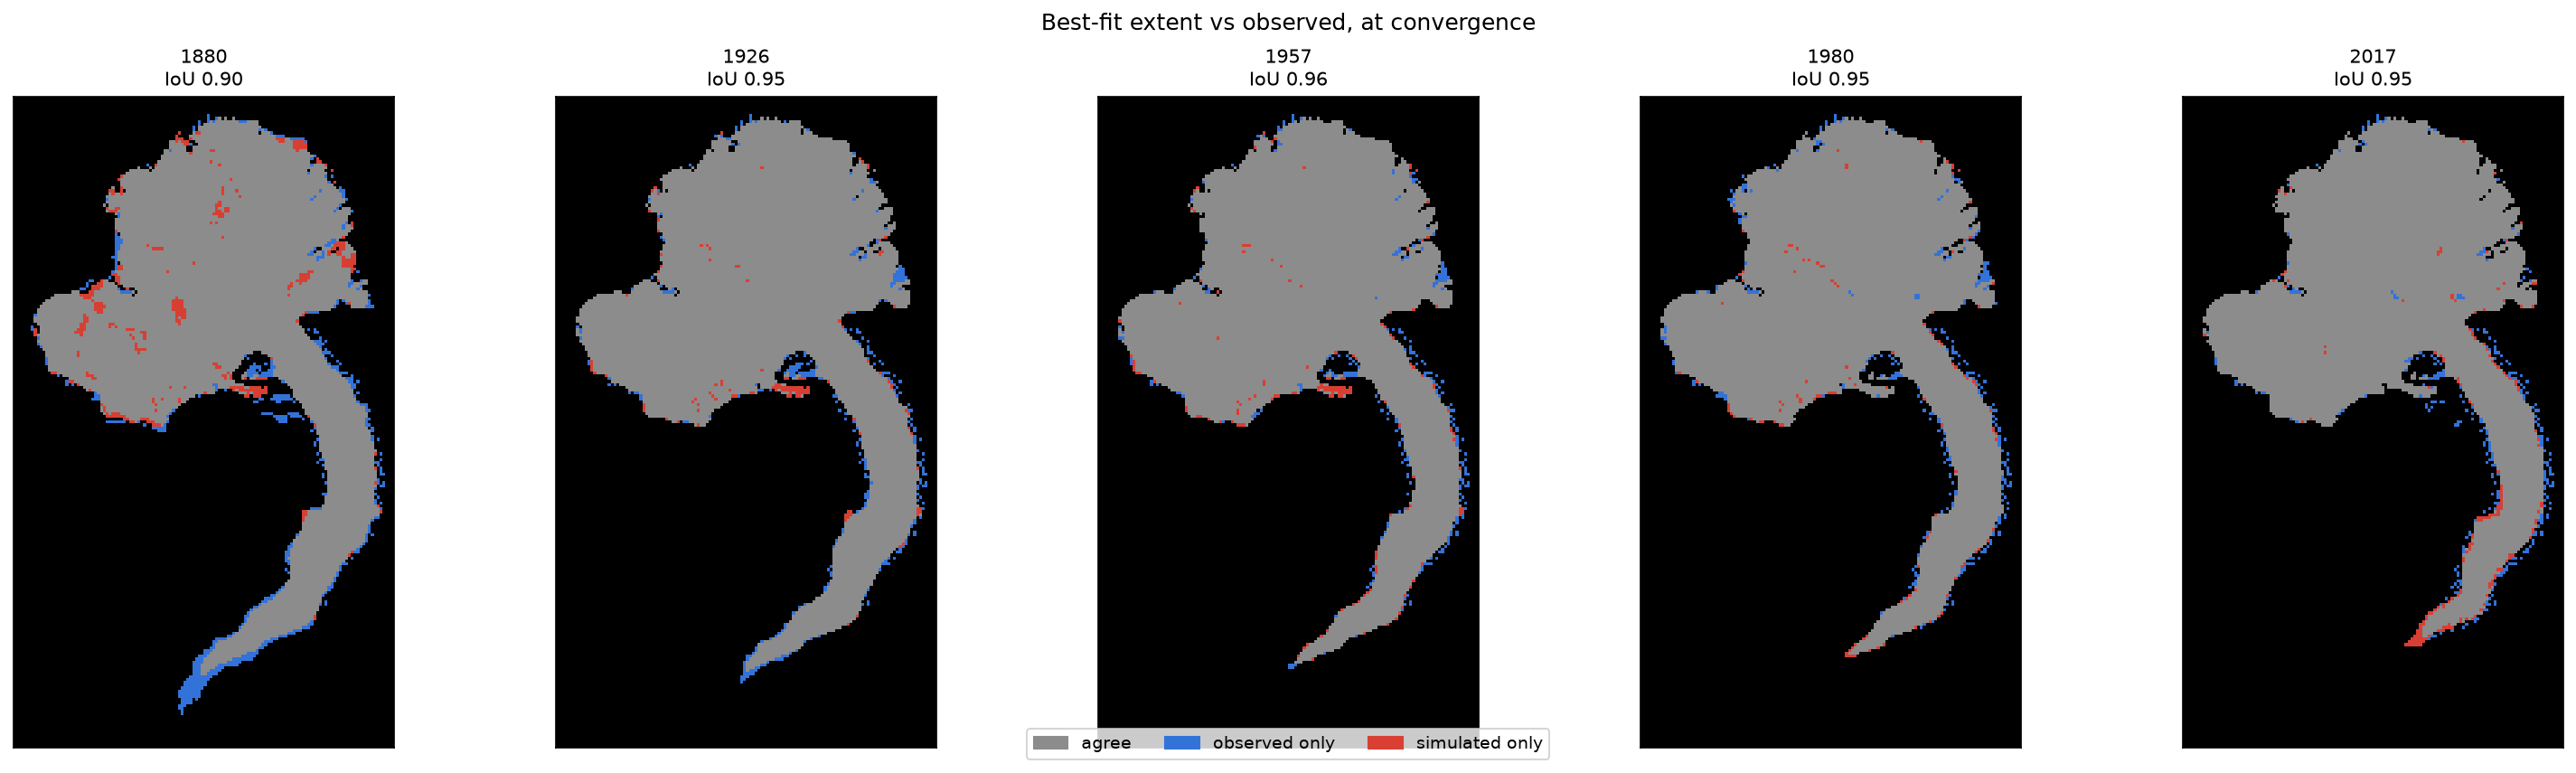

In [10]:
display(Image(filename=f"{RESULTS_MASKED}/extent_comparison.png"))

Grey = agreement, blue = observed ice the model misses, red = simulated ice
the observations do not show. IoU now runs 0.91-0.95 across the five epochs.

The residual colour is not evenly spread, and the pattern is the useful part:
a thin band at the terminus (irreducible at 100 m resolution with a soft
margin), plus scattered patches high in the accumulation basin at the earlier
epochs. The latter are on steep headwall terrain where the model grows a thin
veneer of ice that the real glacier sheds by avalanching -- they are model
error that no temperature can remove, and
[V2](LIA_temperature_inversion_V2.ipynb) shows they were a large enough share
of the objective to steer the inversion.

## 8. Sensitivity: melt factor, precipitation, tau_ref

The temperature inversion's answer is only as good as the four parameters
held fixed while it runs. `tools/sensitivity_lia.py` measures this directly
rather than by argument: hold climate at a constant reference `T`, perturb one
parameter at a time by ±10%/±25%, and convert the resulting shift in the
model's mean terminus position into the temperature bias it's equivalent to
(via `dTerminus/dT`, measured the same way). Read the result as: *"if this
parameter is this far off, the inversion will return a temperature this far
off to compensate."*

In [ ]:
with open("results/sensitivity_lia.json") as f:
    sens = json.load(f)
print(f"reference T = {sens['T_ref']} C   "
      f"dTerminus/dT = {sens['dterm_dT']:+.0f} m/C   "
      f"dIoU/dT = {sens['diou_dT']:+.4f} /C\n")

print(f"{'parameter':12s} {'-25%':>7s} {'-10%':>7s} {'+10%':>7s} {'+25%':>7s}   (deg C bias)")
for name in ("melt_factor", "precip", "tau_ref"):
    vals = {round(r["fraction"], 2): r["dT_equivalent"] for r in sens["perturbations"]
           if r["parameter"] == name}
    print(f"{name:12s} " + "".join(f"{vals.get(f, float('nan')):+7.2f} "
                                   for f in (-0.25, -0.10, 0.10, 0.25)))

In [ ]:
display(Image(filename="results/lia_1700_2017/sensitivity_parameters.png"))

In [ ]:
display(Image(filename="results/lia_1700_2017/sensitivity_iou_flatness.png"))

**The two mass-balance parameters dominate sliding by 5-15x.** A 10%
error in melt factor or precipitation biases the inverted temperature by
~0.3-0.4 C; the same error in tau_ref costs 0.06 C -- below anything this
experiment can resolve. That's physically sensible: terminus position over
centuries is set by mass balance, and ice dynamics mostly set how fast the
glacier gets there, not where it ends up. (The Arrhenius flow-law factor was
dropped from this sweep: at +-25% it moved the inverted temperature by only
0.01-0.06 C in the original 4-parameter run, the smallest effect of any of
the four and well inside noise.)

Two things worth carrying forward:

- **Melt factor is asymmetric** (-25% costs 1.4 C, +25% costs 0.6 C) --
  the PDD ablation term is nonlinear in `T`, so errors in the same parameter
  don't cost the same in both directions.
- **Melt factor and precipitation trade off against each other** (a warmer
  climate melts like a wetter one accumulates) -- what this experiment
  actually constrains is closer to their *ratio* than either one alone. A
  companion inversion that lets precipitation vary, with melt factor fixed by
  independent evidence, would show how much of the apparent "temperature
  signal" is really an accumulation signal in disguise.
- **IoU is a genuinely weak function of every one of these parameters**
  (right-hand panel) -- consistent with the extent-vs-thickness information
  gap in Section 4. This is the main argument for treating any single-run
  answer from this POC as indicative rather than final.

## 9. Conclusions and what to do next

**What this notebook establishes:**

1. The LIA moraine is confirmed as the 1880 margin (100 m median offset,
  86% within 150 m) -- an independent validation of `geology.nc`, and the
  calibration the Younger Dryas moraines will need later.
2. Starting the simulation from today's geometry needs **at least ~380 years
  of spin-up** (start in 1500) to recover the full observed 1880 volume;
  1600 (280 yr) already recovers 97%, but 1500 was chosen for the real run
  to remove that residual as a factor. A shorter spin-up biases the whole
  inversion toward a warmer answer than the data alone would justify, because
  it's compensating for an unrelated initial-condition deficit.
3. Extent-only scoring, while requested, is a genuinely weaker constraint than
  thickness for this glacier -- it loses 34% of its volume but only 6% of
  its net area over the historical record, and mean IoU moves by under 0.01 per
  degree of `T`.
4. **Melt factor and precipitation matter 5-15x more than tau_ref** for the
  inverted temperature (the Arrhenius flow-law factor was dropped from the
  sweep -- at +-25% it moved `T` by only 0.01-0.06 C, the smallest and least
  informative effect of the four originally tested). Any reported uncertainty
  on `T(t)` should be dominated by the priors on melt factor and
  precipitation, not by ice dynamics.
5. `core.inversion.invert_extent` replaces the broken `inversion_extent`
  (hard-coded to 7 epochs, incompatible with the current forward model's
  return signature) with a version that takes an arbitrary set of dated
  epochs and weights.

**The actual result, from the 60-iteration run (1500-2017, lr=0.02):** the
inverted history is flat at ~7.27 C through 1750, then warms to 8.15 C by
1950-2000 -- a **0.90 C** trend. Loss fell 47% and flattened; mean IoU rose
0.900 -> 0.944. The trend emerged only after ~20 iterations of uniform
upward drift, and was still growing at iteration 59, so 0.90 C is a lower
bound. For scale, inverting the constant-temperature terminus curve epoch by
epoch (see V2) says the observations imply about **+1.36 C**, so this run has
recovered roughly two thirds of the required trend.

**Before trusting `T(t)` for a paleoclimate claim:**

- **Fix the conditioning before buying more iterations.** The two-phase
  behaviour above is a parameterization problem, not a budget problem --
  [V2](LIA_temperature_inversion_V2.ipynb) diagnoses it and tests a fix.
- **Quantify uncertainty**, not just a point estimate: an ensemble over the
  melt factor / precipitation prior (Section 8) would turn "T(t) history"
  into "T(t) with error bars," which is what a reconstruction claim needs.
- **Consider adding one thickness observation** (even just 2017, the most
  reliable epoch) as a lightly-weighted term -- Section 4 argues this would
  sharpen the objective substantially, at the cost of no longer being
  extent-only.
- **Reproducing this notebook:** set `RUN_HEAVY_CELLS = True` at the top, or
  run the four scripts in the table at the top of this notebook directly.
